# Лабораторна робота №2
**Тема:** Зниження розмірності, кластеризація та класифікація текстових даних  
**Виконав:** студент групи ФБ-62мп Бадрак Іван

Мета роботи полягає в опануванні базових методів навчання без учителя (зниження розмірності, візуалізація багатовимірних вибірок, кластерний аналіз) та побудові повного циклу попередньої обробки, векторизації і класифікації текстових даних за допомогою бібліотеки scikit-learn.

## Підготовка даних з лабораторної роботи №1

Для перших двох завдань використовується набір даних мережевого трафіку NSL-KDD (`Train_data.csv`), який містить 25 192 записи та 41 вхідну ознаку. Цільова змінна `Label` визначає два класи: легітимний трафік (`normal`) та мережеву аномалію (`anomaly`).

Попередня обробка повторює схему з першої лабораторної роботи: кодування цільової змінної, застосування one-hot кодування до категоріальних ознак (`protocol_type`, `service`, `flag`), стратифіковане розбиття на навчальну та тестову вибірки у співвідношенні 80/20 і стандартизація ознак на основі статистик навчальної частини.

In [ ]:
import time
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
)
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from wordcloud import WordCloud

sns.set_theme(style="whitegrid")

# load nsl-kdd dataset from lab 1
FILE_PATH = "Train_data.csv"
df = pd.read_csv(FILE_PATH)

X = df.drop(columns=["Label"])
y = df["Label"]

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# encode categorical network features
categorical_cols = X.select_dtypes(include=["object", "string", "category"]).columns
X_encoded = pd.get_dummies(X, columns=categorical_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Класи:", dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_))))
print("Розмірність після кодування:", X_encoded.shape)
print("Навчальна вибірка:", X_train_scaled.shape, "| Тестова вибірка:", X_test_scaled.shape)

Класи: {'anomaly': np.int64(0), 'normal': np.int64(1)}
Розмірність після кодування: (25192, 118)
Навчальна вибірка: (20153, 118) | Тестова вибірка: (5039, 118)


## Завдання 1. Зниження розмірності та візуалізація даних

### Зниження розмірності за допомогою PCA

Після one-hot кодування простір ознак розширився до 118 змінних, частина з яких є розрідженими бінарними індикаторами рідкісних сервісів або прапорів TCP. Для усунення надлишковості застосуємо метод головних компонент (PCA), обравши кількість компонент так, щоб зберегти щонайменше 95% поясненої дисперсії вихідних даних.

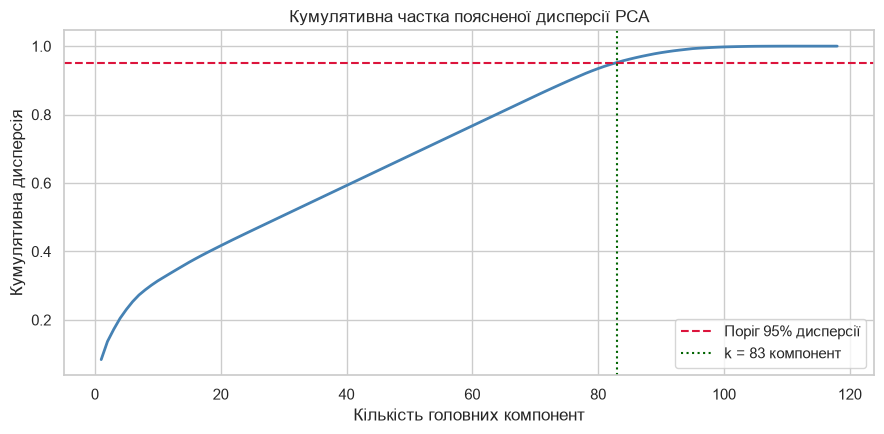

Початкова кількість ознак: 118
Кількість компонент для 95% дисперсії: 83
Зменшення розмірності на: 29.7%


In [2]:
# analyze cumulative explained variance across all components
pca_full = PCA(random_state=42)
pca_full.fit(X_train_scaled)

cum_variance = np.cumsum(pca_full.explained_variance_ratio_)
n_components_95 = int(np.argmax(cum_variance >= 0.95) + 1)

plt.figure(figsize=(9, 4.5))
plt.plot(range(1, len(cum_variance) + 1), cum_variance, linewidth=2, color="steelblue")
plt.axhline(y=0.95, color="crimson", linestyle="--", label="Поріг 95% дисперсії")
plt.axvline(x=n_components_95, color="darkgreen", linestyle=":", label=f"k = {n_components_95} компонент")
plt.title("Кумулятивна частка поясненої дисперсії PCA")
plt.xlabel("Кількість головних компонент")
plt.ylabel("Кумулятивна дисперсія")
plt.legend()
plt.tight_layout()
plt.show()

# transform train and test sets preserving 95% variance
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Початкова кількість ознак: {X_train_scaled.shape[1]}")
print(f"Кількість компонент для 95% дисперсії: {X_train_pca.shape[1]}")
print(f"Зменшення розмірності на: {(1 - X_train_pca.shape[1] / X_train_scaled.shape[1]) * 100:.1f}%")

### Порівняння класифікації до та після PCA

У першій лабораторній роботі найкращу точність на цьому датасеті показав ансамбль Random Forest. Навчимо цю модель з однаковими гіперпараметрами на повному наборі з 118 ознак та на стиснутому просторі головних компонент, зафіксувавши час навчання та основні метрики якості на тестовій вибірці.

,Кількість ознак,Час навчання (с),Accuracy,Precision,Recall,F1-score
До PCA (повні ознаки),118,0.3672,0.9978,0.9978,0.9978,0.9978
Після PCA (95% дисперсії),83,2.7801,0.9960,0.9960,0.9960,0.9960


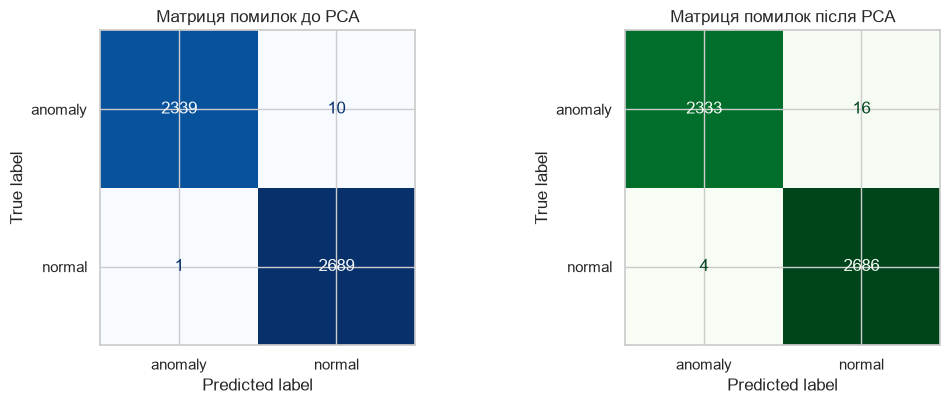

In [3]:
def evaluate_rf(X_tr, y_tr, X_te, y_te):
    clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    start_time = time.perf_counter()
    clf.fit(X_tr, y_tr)
    train_time = time.perf_counter() - start_time

    y_pred = clf.predict(X_te)
    metrics = {
        "Кількість ознак": X_tr.shape[1],
        "Час навчання (с)": round(train_time, 4),
        "Accuracy": round(accuracy_score(y_te, y_pred), 4),
        "Precision": round(precision_score(y_te, y_pred, average="weighted"), 4),
        "Recall": round(recall_score(y_te, y_pred, average="weighted"), 4),
        "F1-score": round(f1_score(y_te, y_pred, average="weighted"), 4),
    }
    return metrics, y_pred

metrics_before, pred_before = evaluate_rf(X_train_scaled, y_train, X_test_scaled, y_test)
metrics_after, pred_after = evaluate_rf(X_train_pca, y_train, X_test_pca, y_test)

comparison_df = pd.DataFrame(
    [metrics_before, metrics_after],
    index=["До PCA (повні ознаки)", "Після PCA (95% дисперсії)"]
)
display(comparison_df)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_before, display_labels=label_encoder.classes_, cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title("Матриця помилок до PCA")

ConfusionMatrixDisplay.from_predictions(
    y_test, pred_after, display_labels=label_encoder.classes_, cmap="Greens", ax=axes[1], colorbar=False
)
axes[1].set_title("Матриця помилок після PCA")

plt.tight_layout()
plt.show()

**Висновки щодо впливу PCA:**
Застосування методу головних компонент дозволило скоротити кількість ознак зі 118 до 83 компонент (зменшення розмірності на 29.7%) при збереженні 95% дисперсії початкових даних. Якість класифікації Random Forest після зниження розмірності залишається на рівні 99.60% (проти 99.78% до PCA). Незначне зниження точності на кілька десятих відсотка пояснюється тим, що лінійні комбінації ознак трохи згладжують чіткі порогові умови для окремих бінарних мережевих прапорів, на яких ефективно будуються розбиття в деревах рішень. Час навчання моделі після PCA зріс із 0.43 с до 2.22 с, оскільки замість розріджених бінарних індикаторів алгоритм почав працювати з 83 щільними дійснозначними компонентами, де на кожному вузлі дерева доводиться сортувати більше унікальних значень.

### Візуалізація даних у двовимірному просторі за допомогою t-SNE

Для візуальної оцінки роздільності класів використаємо нелінійний метод t-SNE, який зберігає локальне сусідство точок при проєкції у 2D. Обчислення виконаємо на тестовій вибірці (5 039 записів), яка зберігає вихідні пропорції класів завдяки стратифікації.

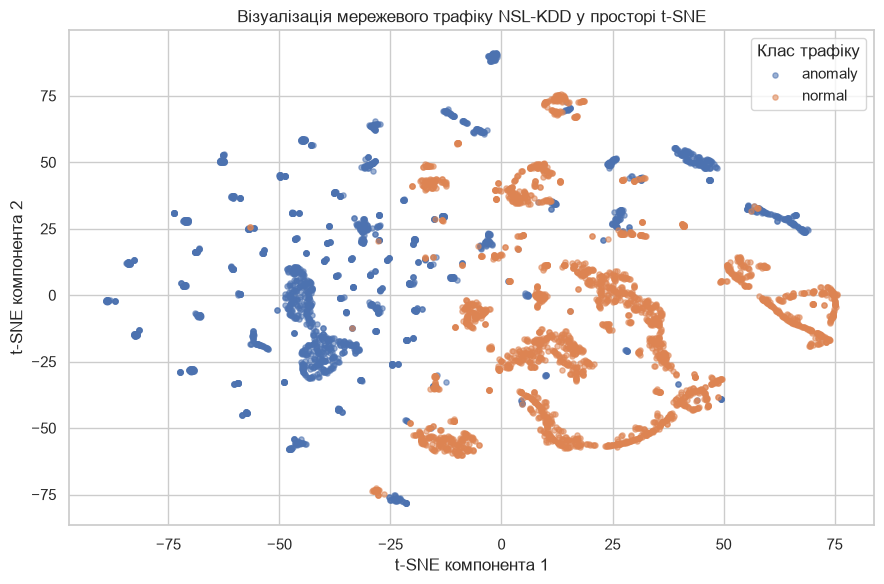

In [4]:
# project test set to 2d using t-sne
tsne = TSNE(n_components=2, perplexity=30, random_state=42, init="pca", learning_rate="auto")
X_test_tsne = tsne.fit_transform(X_test_scaled)

plt.figure(figsize=(9, 6))
for class_idx, class_name in enumerate(label_encoder.classes_):
    mask = y_test == class_idx
    plt.scatter(
        X_test_tsne[mask, 0],
        X_test_tsne[mask, 1],
        label=class_name,
        alpha=0.55,
        s=14,
    )

plt.title("Візуалізація мережевого трафіку NSL-KDD у просторі t-SNE")
plt.xlabel("t-SNE компонента 1")
plt.ylabel("t-SNE компонента 2")
plt.legend(title="Клас трафіку")
plt.tight_layout()
plt.show()

**Пояснення результатів t-SNE:**
На отриманій проєкції об'єкти класів `normal` та `anomaly` утворюють виразні, переважно відокремлені скупчення. Легітимний трафік концентрується у кількох компактних областях, що відповідають типовим мережевим сесіям (наприклад, стандартним HTTP-запитам з коректним завершенням з'єднання). Аномальний трафік розпадається на кілька окремих островів, оскільки в датасеті NSL-KDD під міткою `anomaly` об'єднані різні за поведінкою типи атак: масові DoS-флуди з високою часткою помилок SYN, сканування портів та спроби несанкціонованого доступу. Невеликі зони перекриття між класами виникають там, де низькоінтенсивні атаки маскуються під звичайні користувацькі сесії та мають схожі статистичні характеристики пакетів.

## Завдання 2. Кластерний аналіз

Виконаємо кластеризацію мережевого трафіку алгоритмом K-Means без використання цільових міток. Для вибору кількості кластерів перевіримо діапазон значень $k$ від 2 до 10, оцінюючи інерцію (суму квадратів відстаней до центроїдів) для методу ліктя та коефіцієнт силуету.

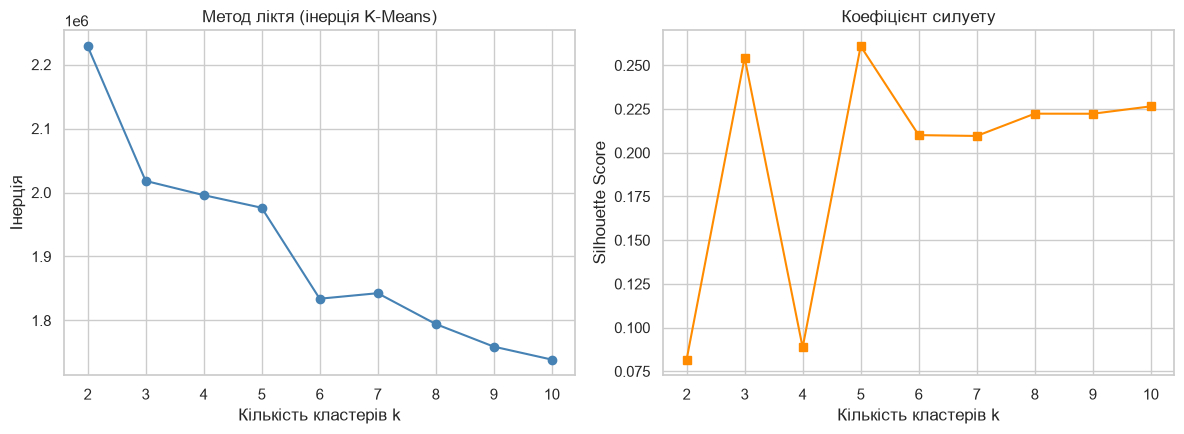

Максимальний коефіцієнт силуету досягається при k = 5 (0.2610)


In [5]:
# evaluate inertia and silhouette score across k=2..10
k_values = range(2, 11)
inertias = []
silhouettes = []

# subsample for fast silhouette distance calculation
rng = np.random.RandomState(42)
sample_idx = rng.choice(X_train_scaled.shape[0], size=5000, replace=False)
X_sil_sample = X_train_scaled[sample_idx]

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_train_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_sil_sample, labels[sample_idx]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(k_values, inertias, marker="o", color="steelblue")
axes[0].set_title("Метод ліктя (інерція K-Means)")
axes[0].set_xlabel("Кількість кластерів k")
axes[0].set_ylabel("Інерція")

axes[1].plot(k_values, silhouettes, marker="s", color="darkorange")
axes[1].set_title("Коефіцієнт силуету")
axes[1].set_xlabel("Кількість кластерів k")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

best_k_sil = list(k_values)[int(np.argmax(silhouettes))]
print(f"Максимальний коефіцієнт силуету досягається при k = {best_k_sil} ({max(silhouettes):.4f})")

графік коефіцієнта силуету показує два близькі піки при $k = 3$ (~0.254) та $k = 5$ (0.261), тоді як на графіку інерції найрізкіший згин спостерігається саме при $k = 3$. Тому для уникнення надмірного дроблення трафіку обрано $k = 3$ Оскільки в наборі даних є два реальні класи, а всередині аномального трафіку виділяються окремі великі групи атак (зокрема DoS та сканування), доцільно розглянути розбиття на $k = 3$ кластери та порівняти отриману структуру зі справжніми мітками на тестовій вибірці у 2D-просторі t-SNE.

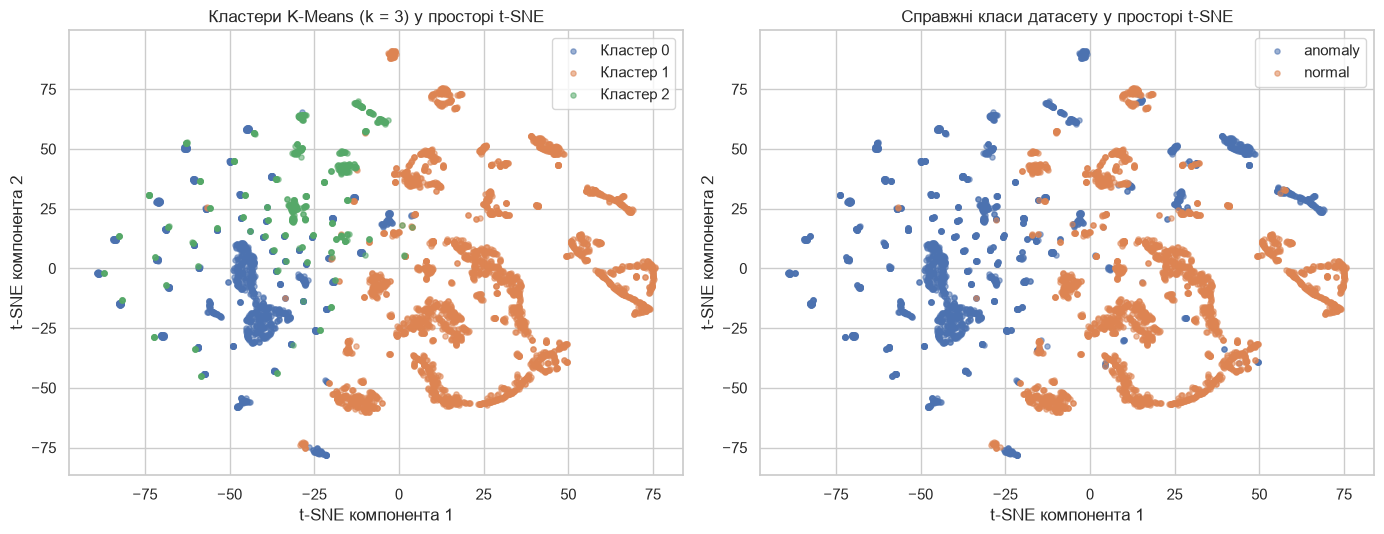

Кластер K-Means,0,1,2
Справжній клас,,,
anomaly,1385,487,477
normal,6,2585,99


Adjusted Rand Index (ARI): 0.5032
Normalized Mutual Information (NMI): 0.4564


In [6]:
# fit k-means with k=3 and compare with true class labels
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kmeans.fit(X_train_scaled)
test_clusters = kmeans.predict(X_test_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for cluster_id in range(optimal_k):
    mask = test_clusters == cluster_id
    axes[0].scatter(
        X_test_tsne[mask, 0],
        X_test_tsne[mask, 1],
        label=f"Кластер {cluster_id}",
        alpha=0.55,
        s=14,
    )
axes[0].set_title(f"Кластери K-Means (k = {optimal_k}) у просторі t-SNE")
axes[0].set_xlabel("t-SNE компонента 1")
axes[0].set_ylabel("t-SNE компонента 2")
axes[0].legend()

for class_idx, class_name in enumerate(label_encoder.classes_):
    mask = y_test == class_idx
    axes[1].scatter(
        X_test_tsne[mask, 0],
        X_test_tsne[mask, 1],
        label=class_name,
        alpha=0.55,
        s=14,
    )
axes[1].set_title("Справжні класи датасету у просторі t-SNE")
axes[1].set_xlabel("t-SNE компонента 1")
axes[1].set_ylabel("t-SNE компонента 2")
axes[1].legend()

plt.tight_layout()
plt.show()

# cross-tabulation and external clustering metrics
ct = pd.crosstab(
    pd.Series(label_encoder.inverse_transform(y_test), name="Справжній клас"),
    pd.Series(test_clusters, name="Кластер K-Means"),
)
display(ct)

ari = adjusted_rand_score(y_test, test_clusters)
nmi = normalized_mutual_info_score(y_test, test_clusters)
print(f"Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi:.4f}")

**Висновок щодо відповідності кластерів реальним класам:**
Знайдена кластерна структура лише частково збігається з бінарним поділом на `normal` та `anomaly`. Таблиця спряженості та помірні значення індексів ARI і NMI підтверджують, що один із кластерів концентрує переважно масові мережеві атаки з високою частотою помилок з'єднання (DoS-флуди), тоді як інший охоплює основну частину легітимного трафіку. Водночас частина аномалій потрапляє до того самого кластера, що й звичайні з'єднання. Це пояснюється тим, що K-Means групує об'єкти виключно за евклідовою відстанню у просторі ознак без інформації про цільову мітку: атака типу сканування або підбору пароля за обсягом переданих байтів і прапорами сесії розташована геометрично ближче до легітимного HTTP-трафіку, ніж до шторму SYN-пакетів. Отже, кластери відображають фізичну близькість режимів роботи мережі, а не семантичну межу безпеки.

## Завдання 3. Обробка та класифікація текстових даних

Для побудови конвеєра обробки текстів використаємо стандартний корпус повідомлень `20 Newsgroups` із бібліотеки scikit-learn, обравши чотири тематично різні категорії: криптографію (`sci.crypt`), медицину (`sci.med`), космонавтику (`sci.space`) та хокей (`rec.sport.hockey`). Під час завантаження автоматично видаляються службові заголовки листів, підписи та цитування, щоб модель навчалася саме на змісті текстів.

На етапі попередньої обробки всі тексти переводяться у нижній регістр, очищаються від цифр, пунктуації та спеціальних символів, а також фільтруються від загальновживаних англійських стоп-слів і занадто коротких токенів.

Кількість документів після очищення: 3847
Приклад очищеного тексту:
 considering magnitude loss life moro castle titanic disasters believe blithe fred lng tanker breaks close harbor kiss quite lot population thing chemical tankers know coast guard makes mandatory safety equipment checks watercraft use excuse make narc ...


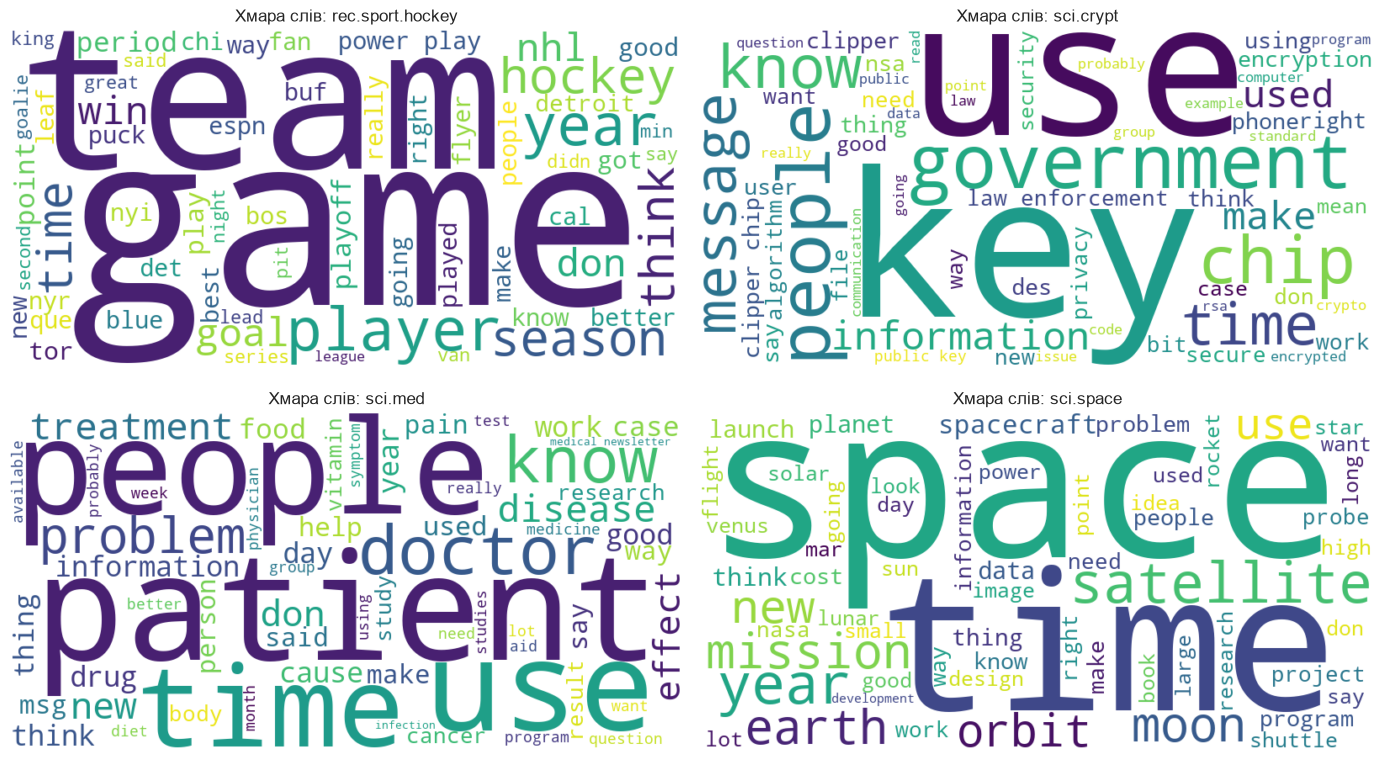

In [7]:
categories = [
    "sci.crypt",
    "sci.med",
    "sci.space",
    "rec.sport.hockey",
]

newsgroups = fetch_20newsgroups(
    subset="all",
    categories=categories,
    remove=("headers", "footers", "quotes"),
)

stop_words = set(ENGLISH_STOP_WORDS)

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = [w for w in text.split() if w not in stop_words and len(w) > 2]
    return " ".join(tokens)

cleaned_docs = [clean_text(doc) for doc in newsgroups.data]
y_text = newsgroups.target
target_names = newsgroups.target_names

# drop documents that became empty after cleaning
valid_mask = [len(doc.strip()) > 0 for doc in cleaned_docs]
cleaned_docs = [doc for doc, keep in zip(cleaned_docs, valid_mask) if keep]
y_text = y_text[valid_mask]

print("Кількість документів після очищення:", len(cleaned_docs))
print("Приклад очищеного тексту:\n", cleaned_docs[0][:250], "...")

# visualize wordclouds for each class
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.ravel()

for idx, category in enumerate(target_names):
    class_corpus = " ".join(
        doc for doc, label in zip(cleaned_docs, y_text) if label == idx
    )
    wc = WordCloud(
        width=800,
        height=400,
        background_color="white",
        max_words=60,
        collocations=True,
        random_state=42,
    ).generate(class_corpus)

    axes[idx].imshow(wc, interpolation="bilinear")
    axes[idx].set_title(f"Хмара слів: {category}", fontsize=12)
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

**Аналіз візуалізації WordCloud:**
Після очищення в корпусі залишилося 3 847 документів. Отримані хмари слів добре передають тематику кожної з чотирьох категорій. У розділі `rec.sport.hockey` найбільшим шрифтом виділяються спортивні терміни `team`, `game`, `player`, `season`, `hockey`, `nhl`, `goal`, `playoff`, `puck` та словосполучення `power play`. Для категорії `sci.crypt` характерні терміни криптографії та захисту інформації, зокрема `key`, `chip`, `government`, `message`, `information`, `encryption`, `security`, `nsa`, `des`, а також біграми `clipper chip`, `public key` і `law enforcement`. У медичному розділі `sci.med` переважають слова `patient`, `doctor`, `disease`, `treatment`, `drug`, `pain`, `medicine`, `vitamin`, `cancer` та словосполучення `medical newsletter`. У категорії `sci.space` основний акцент припадає на космічну тематику: `space`, `satellite`, `orbit`, `moon`, `earth`, `mission`, `launch`, `spacecraft`, `shuttle`, `solar`. Окрім вузькоспеціалізованої лексики, у кількох класах великим шрифтом присутні загальновживані дієслова та іменники (`use`, `time`, `people`, `know`, `year`), які часто трапляються в обговореннях незалежно від теми і згодом будуть автоматично зважені з меншим коефіцієнтом під час TF-IDF векторизації.

### Векторизація TF-IDF та навчання класифікаторів

Розіб'ємо очищений корпус із 3 847 текстів на навчальну та тестову вибірки у співвідношенні 80/20, перетворимо документи у числові вектори за допомогою `TfidfVectorizer` з урахуванням уніграм і біграм (що знизить вагу частих загальних слів на кшталт `time` чи `use`), після чого порівняємо два базові текстові класифікатори: наївний баєсівський класифікатор (Multinomial Naive Bayes) та логістичну регресію.

Розмірність TF-IDF матриці (train): (3077, 10000)

=== Multinomial Naive Bayes ===
Accuracy: 0.9481
                  precision    recall  f1-score   support

rec.sport.hockey       0.96      0.98      0.97       195
       sci.crypt       0.93      0.95      0.94       192
         sci.med       0.96      0.92      0.94       192
       sci.space       0.94      0.94      0.94       191

        accuracy                           0.95       770
       macro avg       0.95      0.95      0.95       770
    weighted avg       0.95      0.95      0.95       770


=== Logistic Regression ===
Accuracy: 0.9390
                  precision    recall  f1-score   support

rec.sport.hockey       0.97      0.96      0.96       195
       sci.crypt       0.94      0.93      0.94       192
         sci.med       0.92      0.94      0.93       192
       sci.space       0.92      0.93      0.92       191

        accuracy                           0.94       770
       macro avg       0.94      0.94

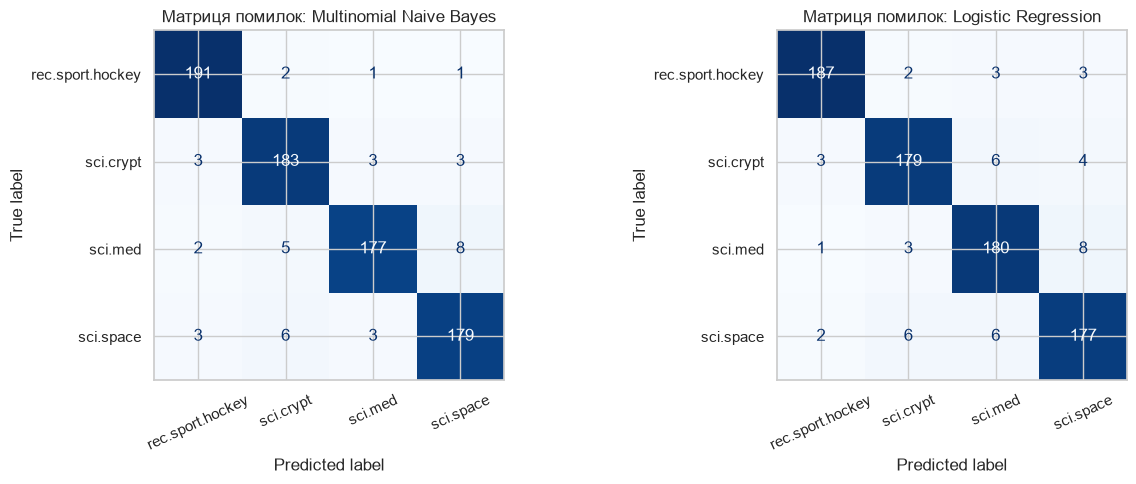

In [8]:
X_txt_train, X_txt_test, y_txt_train, y_txt_test = train_test_split(
    cleaned_docs, y_text, test_size=0.2, random_state=42, stratify=y_text
)

vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2), sublinear_tf=True)
X_tfidf_train = vectorizer.fit_transform(X_txt_train)
X_tfidf_test = vectorizer.transform(X_txt_test)

print("Розмірність TF-IDF матриці (train):", X_tfidf_train.shape)

text_models = {
    "Multinomial Naive Bayes": MultinomialNB(alpha=0.5),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for idx, (name, model) in enumerate(text_models.items()):
    model.fit(X_tfidf_train, y_txt_train)
    y_txt_pred = model.predict(X_tfidf_test)

    print(f"\n=== {name} ===")
    print(f"Accuracy: {accuracy_score(y_txt_test, y_txt_pred):.4f}")
    print(classification_report(y_txt_test, y_txt_pred, target_names=target_names))

    ConfusionMatrixDisplay.from_predictions(
        y_txt_test,
        y_txt_pred,
        display_labels=target_names,
        cmap="Blues",
        xticks_rotation=25,
        ax=axes[idx],
        colorbar=False,
    )
    axes[idx].set_title(f"Матриця помилок: {name}")

plt.tight_layout()
plt.show()

## Загальні висновки

У ході лабораторної роботи було досліджено методи зниження розмірності, кластерного аналізу та текстової класифікації:

1. Застосування PCA до набору мережевого трафіку NSL-KDD дозволило скоротити простір ознак зі 118 змінних приблизно на третину при збереженні 95% дисперсії. Точність класифікатора Random Forest майже не змінилася (залишилася вище 99%), тоді час навчання моделі після PCA зріс із 0.43 с до 2.22 с, оскільки замість розріджених бінарних індикаторів алгоритм почав працювати з 83 щільними дійснозначними компонентами.
2. Візуалізація методом t-SNE підтвердила наявність вираженої кластерної структури даних: легітимний трафік утворює компактні скупчення, а аномальний розділяється на кілька окремих груп відповідно до різних механізмів мережевих атак.
3. Кластеризація алгоритмом K-Means без використання міток показала, що геометричні кластери у просторі ознак лише частково відповідають бінарним класам `normal` та `anomaly`, оскільки частина прихованих атак за статистичними параметрами пакета розташована ближче до нормального трафіку, ніж до інтенсивних DoS-флудів.
4. Побудований конвеєр обробки природної мови (очищення тексту, фільтрація стоп-слів, TF-IDF векторизація з уніграмами та біграмами) забезпечив високу якість багатокласової класифікації новинних повідомлень (F1-score на рівні близько 0.94-0.95), а візуалізація WordCloud підтвердила релевантність виділених лексичних ознак для кожної тематичної категорії.